# Previsão de Churn de Clientes de um Ginásio

**Projeto de Inteligência Artificial · CTeSP DAIA · IPGT · 2026/2027**
Alisson Alencar · Giuliana Finochio — Docente: Jorge Pereira Duque

**Objetivo:** prever se um cliente vai cancelar a subscrição do ginásio no mês seguinte (*churn*), para que a equipa de retenção saiba quem contactar primeiro.

**Pipeline implementado:**

`dados brutos → limpeza → divisão treino/teste → pré-processamento → modelo → avaliação → modelo guardado`

O notebook corre do princípio ao fim sem intervenção manual (*Runtime → Run all* no Colab).

## 0. Configuração

Importamos as bibliotecas e fixamos a semente aleatória (`RANDOM_STATE = 42`) para que os resultados sejam sempre os mesmos — é isto que torna o projeto **reprodutível**.

In [1]:
import json
import urllib.request
import warnings
import zipfile
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score)
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Em macOS com numpy 2.x surgem avisos falsos "encountered in matmul" (no Colab não aparecem).
warnings.filterwarnings("ignore", message=".*encountered in matmul", category=RuntimeWarning)

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET = "Churn"

DATA_PATH = Path("data/gym_churn_us.csv")
MODEL_PATH = Path("models/pipeline_churn.joblib")
OUT_DIR = Path("outputs")
for p in (DATA_PATH.parent, MODEL_PATH.parent, OUT_DIR):
    p.mkdir(exist_ok=True)

## 1. Obter os dados

Dataset: [*Gym customers features and churn*](https://www.kaggle.com/datasets/adrianvinueza/gym-customers-features-and-churn) (Kaggle, licença CC BY-NC-SA 4.0).

Se o ficheiro `data/gym_churn_us.csv` ainda não existir (por exemplo, numa sessão nova do Colab), a célula descarrega-o automaticamente do Kaggle. **O CSV original nunca é alterado** — só é lido.

In [2]:
KAGGLE_URL = "https://www.kaggle.com/api/v1/datasets/download/adrianvinueza/gym-customers-features-and-churn"

if not DATA_PATH.exists():
    zip_path = DATA_PATH.parent / "dataset.zip"
    urllib.request.urlretrieve(KAGGLE_URL, zip_path)
    with zipfile.ZipFile(zip_path) as z:
        z.extract("gym_churn_us.csv", DATA_PATH.parent)
    zip_path.unlink()
    print("Dataset descarregado do Kaggle.")
else:
    print("Dataset já existe localmente.")

Dataset já existe localmente.


## 2. Compreensão dos dados

Carregamos o CSV e olhamos para a estrutura: número de linhas e colunas, tipos, valores omissos e distribuição da variável-alvo.

In [3]:
df_raw = pd.read_csv(DATA_PATH)
print(f"{df_raw.shape[0]} linhas × {df_raw.shape[1]} colunas")
df_raw.head()

4000 linhas × 14 colunas


,gender,Near_Location,Partner,Promo_friends,Phone,Contract_period,Group_visits,Age,Avg_additional_charges_total,Month_to_end_contract,Lifetime,Avg_class_frequency_total,Avg_class_frequency_current_month,Churn
0,1,1,1,1,0,6,1,29,14.227470,5.0,3,0.020398,0.000000,0
1,0,1,0,0,1,12,1,31,113.202938,12.0,7,1.922936,1.910244,0
2,0,1,1,0,1,1,0,28,129.448479,1.0,2,1.859098,1.736502,0
3,0,1,1,1,1,12,1,33,62.669863,12.0,2,3.205633,3.357215,0
4,1,1,1,1,1,1,0,26,198.362265,1.0,3,1.113884,1.120078,0


In [4]:
resumo = pd.DataFrame({
    "tipo": df_raw.dtypes.astype(str),
    "omissos": df_raw.isna().sum(),
    "valores_distintos": df_raw.nunique(),
})
print(f"Duplicados: {df_raw.duplicated().sum()}")
resumo

Duplicados: 0


,tipo,omissos,valores_distintos
gender,int64,0,2
Near_Location,int64,0,2
Partner,int64,0,2
Promo_friends,int64,0,2
Phone,int64,0,2
Contract_period,int64,0,3
Group_visits,int64,0,2
Age,int64,0,23
Avg_additional_charges_total,float64,0,4000
Month_to_end_contract,float64,0,12


In [5]:
print("Distribuição da variável-alvo (Churn):")
print(df_raw[TARGET].value_counts().rename({0: "Fica (0)", 1: "Churn (1)"}))
print(f"\nTaxa de churn: {df_raw[TARGET].mean():.1%}  → classes desequilibradas")

Distribuição da variável-alvo (Churn):
Churn
Fica (0)     2939
Churn (1)    1061
Name: count, dtype: int64

Taxa de churn: 26.5%  → classes desequilibradas


**Que variáveis mais se relacionam com o churn?** A correlação com o alvo dá uma primeira ideia. Valores negativos significam que, quanto maior a variável, menor o churn.

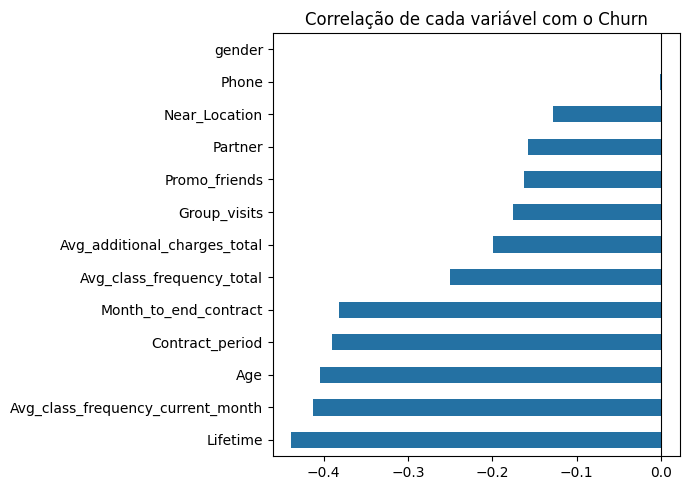

In [6]:
corr = df_raw.corr()[TARGET].drop(TARGET).sort_values()
ax = corr.plot.barh(figsize=(7, 5), color=["#2471a3" if v < 0 else "#c0392b" for v in corr])
ax.set_title("Correlação de cada variável com o Churn")
ax.axvline(0, color="black", linewidth=0.8)
plt.tight_layout()
plt.show()

In [7]:
# Pares de variáveis muito correlacionadas entre si (importante para interpretar os coeficientes)
c = df_raw.corr()
print(f"Avg_class_frequency_total vs current_month: r = {c.loc['Avg_class_frequency_total', 'Avg_class_frequency_current_month']:.2f}")
print(f"Contract_period vs Month_to_end_contract:   r = {c.loc['Contract_period', 'Month_to_end_contract']:.2f}")

Avg_class_frequency_total vs current_month: r = 0.95
Contract_period vs Month_to_end_contract:   r = 0.97


**Decisão:** separamos as variáveis em três grupos, porque cada grupo precisa de um tratamento diferente no pré-processamento:

- **binárias** (0/1): já estão codificadas;
- **categórica**: `Contract_period` (1, 6 ou 12 meses) — é um tipo de plano, não uma quantidade contínua, por isso usamos *one-hot*;
- **numéricas contínuas**: precisam de normalização para que os coeficientes sejam comparáveis.

In [8]:
BINARY_FEATURES = ["gender", "Near_Location", "Partner", "Promo_friends", "Phone", "Group_visits"]
CATEGORICAL_FEATURES = ["Contract_period"]
NUMERIC_FEATURES = ["Age", "Avg_additional_charges_total", "Month_to_end_contract", "Lifetime",
                    "Avg_class_frequency_total", "Avg_class_frequency_current_month"]
IRRELEVANT_COLUMNS = ["customer_id", "id", "ID"]  # identificadores (não existem neste dataset)

## 3. Limpeza

Retiramos identificadores e duplicados, e linhas sem alvo. Estas operações **não aprendem nada com os dados** (não calculam médias nem medianas), por isso podem ser feitas antes da divisão sem risco de fuga de informação.

Os valores omissos **não** são tratados aqui: a imputação é feita dentro do pipeline, aprendida só com o treino.

In [9]:
df = df_raw.copy()
df = df.drop(columns=[col for col in IRRELEVANT_COLUMNS if col in df.columns])
n_dup = df.duplicated().sum()
df = df.drop_duplicates().dropna(subset=[TARGET])
print(f"Duplicados removidos: {n_dup} · linhas finais: {len(df)}")

X = df[NUMERIC_FEATURES + CATEGORICAL_FEATURES + BINARY_FEATURES]
y = df[TARGET]

Duplicados removidos: 0 · linhas finais: 4000


## 4. Divisão treino/teste

Dividimos **antes** de qualquer transformação aprendida: 80 % treino, 20 % teste, `random_state=42` e `stratify=y` para que ambos os conjuntos tenham a mesma proporção de churn (26,5 %).

O conjunto de teste fica "fechado" até à avaliação final.

In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f"Treino: {len(X_train)} clientes (churn {y_train.mean():.1%})")
print(f"Teste:  {len(X_test)} clientes (churn {y_test.mean():.1%})")

Treino: 3200 clientes (churn 26.5%)
Teste:  800 clientes (churn 26.5%)


## 5. Pipeline: pré-processamento + modelo

O `ColumnTransformer` aplica a cada grupo de variáveis o tratamento certo:

| Grupo | Imputação | Transformação |
|---|---|---|
| Numéricas | mediana | `StandardScaler` (normalização) |
| Categórica | moda | `OneHotEncoder` (codificação) |
| Binárias | moda | — |

Tudo fica dentro de um único `Pipeline` com a **Regressão Logística**. Quando chamamos `.fit()` com o treino, as medianas, modas, médias e desvios-padrão são calculados **só com o treino** e depois aplicados ao teste — é assim que se evita a fuga de informação.

In [11]:
numeric = Pipeline([("imputacao", SimpleImputer(strategy="median")),
                    ("normalizacao", StandardScaler())])
categorical = Pipeline([("imputacao", SimpleImputer(strategy="most_frequent")),
                        ("codificacao", OneHotEncoder(handle_unknown="ignore"))])
binary = Pipeline([("imputacao", SimpleImputer(strategy="most_frequent"))])

preprocess = ColumnTransformer([
    ("num", numeric, NUMERIC_FEATURES),
    ("cat", categorical, CATEGORICAL_FEATURES),
    ("bin", binary, BINARY_FEATURES),
])

pipe = Pipeline([
    ("preprocessamento", preprocess),
    ("modelo", LogisticRegression(max_iter=1000, random_state=RANDOM_STATE)),
])
pipe

Pipeline(steps=[('preprocessamento',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputacao',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('normalizacao',
                                                                   StandardScaler())]),
                                                  ['Age',
                                                   'Avg_additional_charges_total',
                                                   'Month_to_end_contract',
                                                   'Lifetime',
                                                   'Avg_class_frequency_total',
                                                   'Avg_class_frequency_current_month']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputacao',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('codificacao',
                                                                   OneHotEncoder(handle_unknown='ignore'))]),
                                                  ['Contract_period']),
                                                 ('bin',
                                                  Pipeline(steps=[('imputacao',
                                                                   SimpleImputer(strategy='most_frequent'))]),
                                                  ['gender', 'Near_Location',
                                                   'Partner', 'Promo_friends',
                                                   'Phone',
                                                   'Group_visits'])])),
                ('modelo', LogisticRegression(max_iter=1000, random_state=42))])

### 5.1 Baseline

Para saber se o modelo vale a pena, comparamos com um modelo "ingénuo": o `DummyClassifier` que prevê sempre a classe mais frequente (o cliente fica).

In [12]:
baseline = DummyClassifier(strategy="most_frequent")
baseline.fit(X_train, y_train)
y_pred_base = baseline.predict(X_test)

### 5.2 Validação cruzada (só no treino)

Antes de olhar para o teste, verificamos a estabilidade do modelo com validação cruzada estratificada de 5 *folds* sobre o treino.

In [13]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv_f1 = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
print("F1 por fold:", np.round(cv_f1, 3))
print(f"F1 médio = {cv_f1.mean():.3f} ± {cv_f1.std():.3f}")

F1 por fold: [0.873 0.857 0.852 0.878 0.831]
F1 médio = 0.858 ± 0.017


### 5.3 Treino final

In [14]:
pipe.fit(X_train, y_train)
y_pred = pipe.predict(X_test)
y_proba = pipe.predict_proba(X_test)[:, 1]

## 6. Avaliação no conjunto de teste

Como as classes estão desequilibradas, a *accuracy* engana. Usamos as métricas da classe **churn**:

- **Precision** — dos clientes que o modelo sinaliza, quantos saem mesmo?
- **Recall** — dos clientes que saem, quantos o modelo apanha? *(a métrica mais importante para o negócio)*
- **F1** — equilíbrio entre as duas.

**Critério de sucesso:** recall ≥ 0,75 e F1 claramente acima do baseline.

In [15]:
def evaluate(name, y_true, y_pred, y_proba=None):
    m = {"modelo": name,
         "precision": precision_score(y_true, y_pred, zero_division=0),
         "recall": recall_score(y_true, y_pred, zero_division=0),
         "f1": f1_score(y_true, y_pred, zero_division=0),
         "matriz_confusao": confusion_matrix(y_true, y_pred).tolist()}
    if y_proba is not None:
        m["roc_auc"] = roc_auc_score(y_true, y_proba)
    return m

m_base = evaluate("Baseline (DummyClassifier)", y_test, y_pred_base)
m_lr = evaluate("Regressão Logística", y_test, y_pred, y_proba)
m_lr["cv_f1_media"], m_lr["cv_f1_desvio"] = cv_f1.mean(), cv_f1.std()

pd.DataFrame([m_base, m_lr]).drop(columns="matriz_confusao").set_index("modelo").round(3)

,precision,recall,f1,roc_auc,cv_f1_media,cv_f1_desvio
modelo,,,,,,
Baseline (DummyClassifier),0.000,0.000,0.000,NaN,NaN,NaN
Regressão Logística,0.884,0.825,0.854,0.977,0.858,0.017


In [16]:
print(classification_report(y_test, y_pred, target_names=["Fica (0)", "Churn (1)"], digits=3))

              precision    recall  f1-score   support

    Fica (0)      0.939     0.961     0.950       588
   Churn (1)      0.884     0.825     0.854       212

    accuracy                          0.925       800
   macro avg      0.911     0.893     0.902       800
weighted avg      0.924     0.925     0.924       800



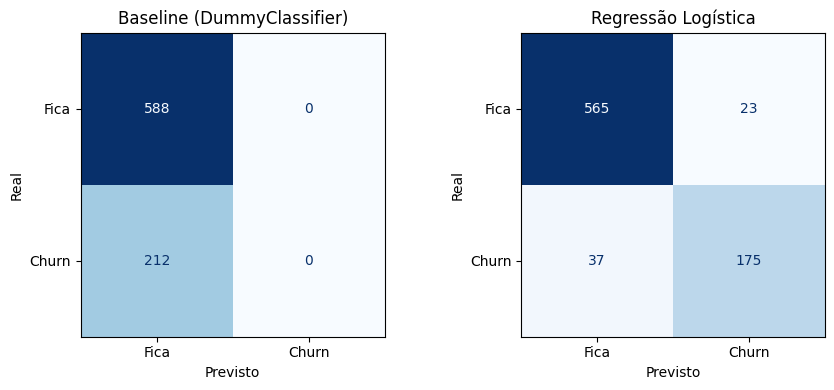

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(9, 4))
for ax, (title, pred) in zip(axes, [("Baseline (DummyClassifier)", y_pred_base),
                                    ("Regressão Logística", y_pred)]):
    ConfusionMatrixDisplay.from_predictions(y_test, pred, display_labels=["Fica", "Churn"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Previsto")
    ax.set_ylabel("Real")
fig.tight_layout()
fig.savefig(OUT_DIR / "matriz_confusao.png", dpi=200)
plt.show()

**Leitura:** o baseline acerta em ~73,5 % dos clientes (*accuracy*) mas **não deteta nenhum** churn (recall = 0) — é inútil para o negócio. A Regressão Logística apanha a grande maioria dos clientes que vão sair, com poucos falsos alarmes, e cumpre o critério de sucesso.

## 7. Interpretação: os coeficientes mais influentes

Como as variáveis numéricas foram normalizadas, os coeficientes são comparáveis: cada um indica o efeito de **+1 desvio-padrão** na variável sobre o log-odds de churn.

- coeficiente **negativo** → reduz o risco de churn;
- coeficiente **positivo** → aumenta o risco de churn;
- `odds_ratio = exp(coef)` → por quanto se multiplicam as probabilidades relativas (*odds*).

In [18]:
names = [n.split("__", 1)[1] for n in pipe.named_steps["preprocessamento"].get_feature_names_out()]
coefs = pd.DataFrame({"variavel": names, "coeficiente": pipe.named_steps["modelo"].coef_[0]})
coefs["odds_ratio"] = np.exp(coefs["coeficiente"])
coefs = coefs.reindex(coefs["coeficiente"].abs().sort_values(ascending=False).index).reset_index(drop=True)
coefs.to_csv(OUT_DIR / "coeficientes.csv", index=False)
coefs.round(3)

,variavel,coeficiente,odds_ratio
0,Avg_class_frequency_current_month,-4.215,0.015
1,Lifetime,-3.756,0.023
2,Avg_class_frequency_total,3.136,23.015
3,Age,-1.184,0.306
4,Month_to_end_contract,-0.738,0.478
5,Group_visits,-0.733,0.481
6,Contract_period_1,0.656,1.927
7,Contract_period_12,-0.579,0.560
8,Avg_additional_charges_total,-0.575,0.563
9,Promo_friends,-0.459,0.632


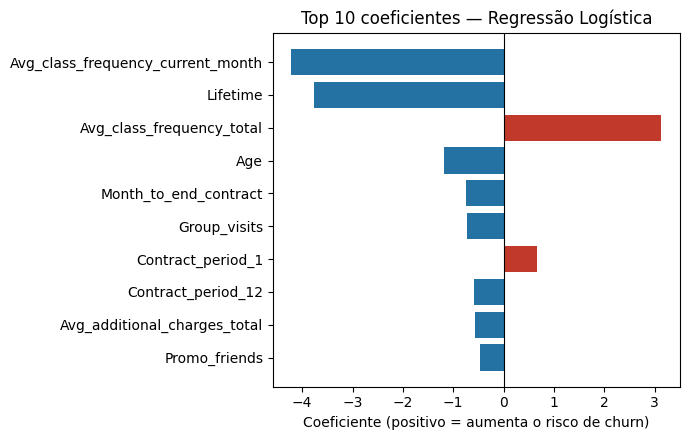

In [19]:
top = coefs.head(10).iloc[::-1]
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.barh(top["variavel"], top["coeficiente"],
        color=["#c0392b" if v > 0 else "#2471a3" for v in top["coeficiente"]])
ax.axvline(0, color="black", linewidth=0.8)
ax.set_xlabel("Coeficiente (positivo = aumenta o risco de churn)")
ax.set_title("Top 10 coeficientes — Regressão Logística")
fig.tight_layout()
fig.savefig(OUT_DIR / "coeficientes.png", dpi=200)
plt.show()

**Os 3 coeficientes mais influentes:**

1. **`Avg_class_frequency_current_month` (negativo)** — quanto mais o cliente frequenta o ginásio no mês atual, menor o risco de sair.
2. **`Lifetime` (negativo)** — clientes com mais meses de casa são muito mais fiéis; os primeiros meses são o período crítico.
3. **`Avg_class_frequency_total` (positivo)** — à primeira vista parece estranho, mas esta variável está muito correlacionada com a do mês atual (r ≈ 0,95). Lidas em conjunto: *para a mesma frequência atual*, quem tinha um histórico de frequência mais alto tem mais risco. Ou seja, **o sinal de alerta é a queda da frequência** face ao hábito do cliente.

**Implicação para o negócio:** monitorizar clientes novos e clientes cuja frequência caiu face à sua média, e atuar antes do fim do mês.

## 8. Guardar o pipeline completo

Guardamos o pipeline inteiro (pré-processamento + modelo) com `joblib`. Assim, quem o usar só precisa de lhe passar os dados brutos de um cliente — não tem de repetir a imputação nem a normalização.

Para confirmar, recarregamos o ficheiro e verificamos que dá exatamente as mesmas previsões.

In [20]:
joblib.dump(pipe, MODEL_PATH)
reloaded = joblib.load(MODEL_PATH)
assert (reloaded.predict(X_test) == y_pred).all(), "O pipeline recarregado não reproduz as previsões"
print(f"Pipeline guardado em {MODEL_PATH} e verificado.")

with open(OUT_DIR / "metricas.json", "w", encoding="utf-8") as f:
    json.dump({"baseline": m_base, "regressao_logistica": m_lr}, f, indent=2, ensure_ascii=False)
print(f"Métricas guardadas em {OUT_DIR / 'metricas.json'}")

Pipeline guardado em models/pipeline_churn.joblib e verificado.
Métricas guardadas em outputs/metricas.json


### Exemplo de utilização

Como o ginásio usaria o modelo no início de cada mês: calcular a probabilidade de churn de cada cliente e ordenar a lista para a equipa de retenção.

In [21]:
modelo = joblib.load(MODEL_PATH)
clientes = X_test.copy()
clientes["prob_churn"] = modelo.predict_proba(clientes)[:, 1]
clientes.sort_values("prob_churn", ascending=False).head(10)[
    ["Age", "Lifetime", "Contract_period", "Avg_class_frequency_current_month", "prob_churn"]
].round(3)

,Age,Lifetime,Contract_period,Avg_class_frequency_current_month,prob_churn
221,27,0,1,0.006,1.000
3832,22,0,1,0.055,1.000
2907,21,0,1,0.435,1.000
1413,23,0,1,0.000,1.000
1414,24,1,1,0.346,0.999
3247,26,0,1,0.085,0.999
3205,23,0,1,1.111,0.999
1982,21,1,1,0.000,0.999
1288,25,0,1,0.093,0.999
46,26,0,1,0.000,0.999


## 9. Conclusão

- O pipeline corre do princípio ao fim sem intervenção manual e é reprodutível (`random_state=42`).
- A fuga de informação é evitada dividindo os dados antes de aprender qualquer transformação e mantendo todo o pré-processamento dentro do `Pipeline`.
- A Regressão Logística supera claramente o baseline e cumpre o critério de sucesso (recall ≥ 0,75).
- Os fatores mais importantes são a frequência recente, a antiguidade e a **queda de frequência** face ao histórico.

**Limitações e trabalho futuro:** as variáveis do mês atual pressupõem que estão disponíveis no momento da previsão; seria útil ajustar o limiar de decisão ao custo real de cada ação de retenção e monitorizar o modelo ao longo do tempo.